# FNNs on MNIST 

The plan:

1. Train an FNN on MNIST
2. Ask which pixels it's looking at 


 Neural nets 

A neuron: weighted sum + bias, then an activation: $y = f(w \cdot x + b)$
Stack them into layers.
Training: predict → measure the error (loss) → backprop → gradient descent → repeat
Activation functions add non-linearity; without it, a stack of layers collapses into one linear layer

## Setup

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)  # fix seeds so runs are reproducible
np.random.seed(42)

# gpu if there is one, else apple mps, else cpu
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"PyTorch {torch.__version__} | NumPy {np.__version__} | device: {device}")


PyTorch 2.14.1 | NumPy 2.5.4 | device: mps


## MNIST

60k train / 10k test, 28×28 greyscale digits, labels 0-9. Pixels get scaled to [0, 1] and normalised.

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),                            # pixels -> [0, 1] tensor
    transforms.Normalize((0.1307,), (0.3081,)),       # MNIST's global mean and std
])

train_set = torchvision.datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_set = torchvision.datasets.MNIST(root="data", train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=128, shuffle=True)  # smaller batches train faster
test_loader = torch.utils.data.DataLoader(test_set, batch_size=1024, shuffle=False)

print(f"Train: {len(train_set):,} images | Test: {len(test_set):,} images")


Train: 60,000 images | Test: 10,000 images


Let's look at them

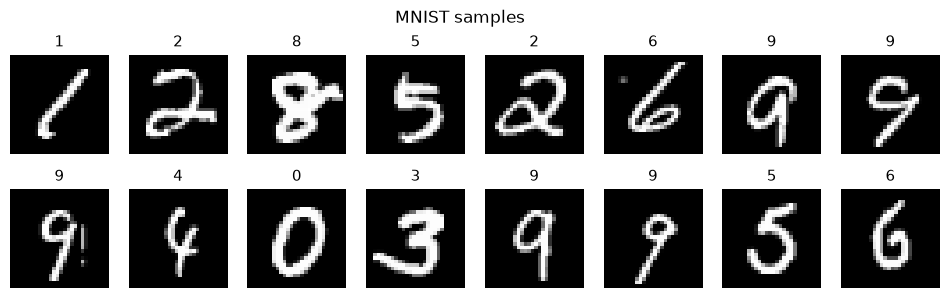

In [4]:
images, labels = next(iter(train_loader))  # grab one batch
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for ax, img, label in zip(axes.flat, images, labels):  # zip stops after the 16 axes
    ax.imshow(img.squeeze(), cmap="gray")  # drop the channel dim, grayscale
    ax.axis("off")
fig.suptitle("MNIST samples", y=1)
plt.show()


## Flatten

The FNN wants a flat vector, so 28×28 → 784 numbers. Now its not 2D but viewed to the NN more like this

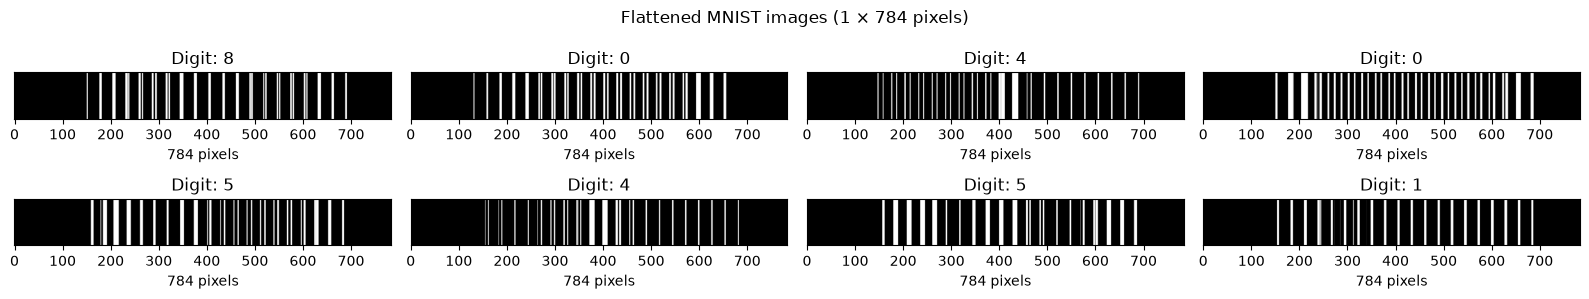

In [14]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(16, 3))

for ax, img, label in zip(axes.flat, images, labels):
    flattened_img = img.flatten().unsqueeze(0)  # (1, 28, 28) -> (1, 784): image as a flat vector

    ax.imshow(flattened_img, cmap="gray", aspect="auto", vmin=0, vmax=1)  # imshow draws a vector as a strip
    ax.set_xlabel("pixels")
    ax.set_yticks([])  # rows carry no meaning here

fig.suptitle("Flattened MNIST images")
plt.tight_layout()
plt.show()


## The model

784 → 256 → 128 → 10, with ReLU in between. The output is 10 logits, one score per digit; highest wins.

In [15]:
class FNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),          # (B, 1, 28, 28) -> (B, 784): image -> vector
            nn.Linear(784, 256),
            nn.Tanh(),             # squashes to (-1, 1); adds the non-linearity
            nn.Linear(256, 128),
            nn.Tanh(),
            nn.Linear(128, 10),    # 10 logits, one per digit class
        )

    def forward(self, x):
        return self.net(x)

model = FNN().to(device)
print(model)
print(f"\n{sum(p.numel() for p in model.parameters()):,} trainable parameters")


FNN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): Tanh()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): Tanh()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

235,146 trainable parameters


## Train it

Cross-entropy loss, Adam (lr 1e-3), 5 epochs.

This is the boilerplate for evaluating a model in torch 

We're using Adam cause faster convergence.

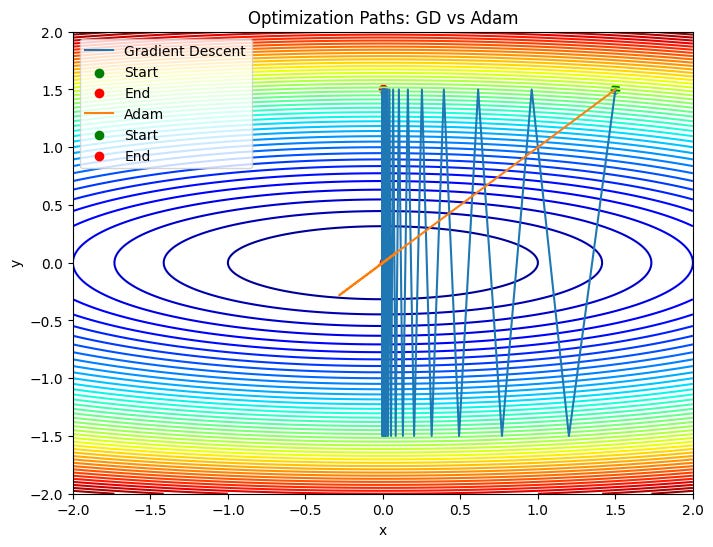

In [ ]:

def evaluate(model, loader):
    model.eval()  # freeze weights, switch off training behaviour
    correct = 0
    with torch.no_grad():  # no gradients needed for testing
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
    return correct / len(loader.dataset)


def train(model, loader, epochs=5):
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, correct = 0.0, 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()      # clear old gradients
            logits = model(x)
            loss = F.cross_entropy(logits, y)
            loss.backward()      # backprop: gradient of loss with respect to every parameter
            opt.step()           # gradient descent step
            total_loss += loss.item() * y.size(0)   # weight loss by batch size
            correct += (logits.argmax(1) == y).sum().item()
        history.append({
            "epoch": epoch,
            "loss": total_loss / len(loader.dataset),
            "train_acc": correct / len(loader.dataset),
            "test_acc": evaluate(model, test_loader),
        })
        h = history[-1]
        print(f"epoch {epoch} | loss {h['loss']:.4f} | train acc {h['train_acc']:.4f} | test acc {h['test_acc']:.4f}")
    return history


history = train(model, train_loader, epochs=5)


epoch 1 | loss 0.2692 | train acc 0.9188 | test acc 0.9607
epoch 2 | loss 0.1026 | train acc 0.9683 | test acc 0.9723
epoch 3 | loss 0.0691 | train acc 0.9786 | test acc 0.9750
epoch 4 | loss 0.0516 | train acc 0.9836 | test acc 0.9782
epoch 5 | loss 0.0402 | train acc 0.9862 | test acc 0.9792


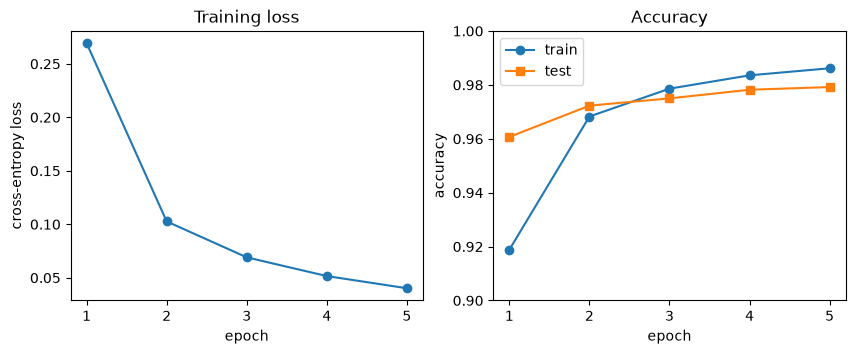

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
epochs = [h["epoch"] for h in history]
ax1.plot(epochs, [h["loss"] for h in history], "o-")
ax1.set(xlabel="epoch", ylabel="cross-entropy loss", title="Training loss")
ax2.plot(epochs, [h["train_acc"] for h in history], "o-", label="train")
ax2.plot(epochs, [h["test_acc"] for h in history], "s-", label="test")  # a growing gap would be overfitting
ax2.set(xlabel="epoch", ylabel="accuracy", title="Accuracy", ylim=(0.9, 1.0))
ax2.legend()
plt.show()


## Results


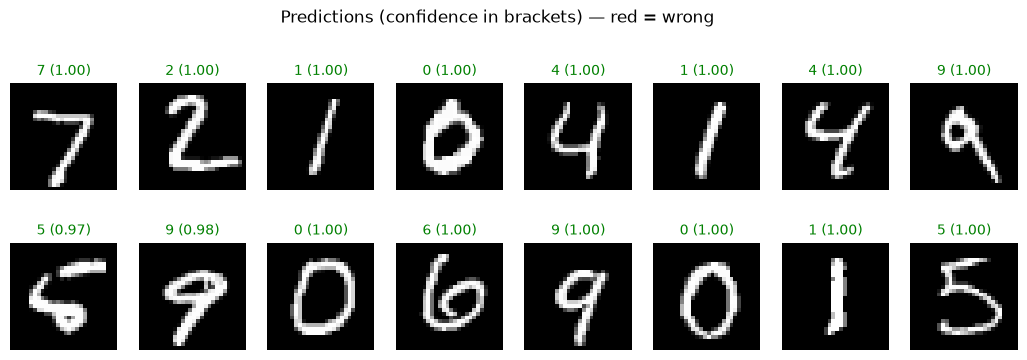

Final test accuracy: 97.92%


In [8]:
model.eval()
x, y = next(iter(test_loader))
with torch.no_grad():
    probs = F.softmax(model(x.to(device)), dim=1).cpu()  # logits -> probabilities

fig, axes = plt.subplots(2, 8, figsize=(13, 3.8))
for ax, img, lab, p in zip(axes.flat, x, y, probs):
    pred = p.argmax().item()  # highest probability wins
    ax.imshow(img.squeeze(), cmap="gray")
    color = "green" if pred == lab.item() else "red"
    ax.set_title("correct" if pred == lab.item() else "wrong", color=color, fontsize=10)
    ax.axis("off")
fig.suptitle("Predictions — red = wrong", y=1.04)
plt.show()

print(f"Final test accuracy: {evaluate(model, test_loader):.2%}")


## What's it looking at?

Saliency map = $|\partial \text{score}_{\hat{y}} / \partial x_i|$, if a pixel's gradient is big, changing it changes the decision, so the net "cares" about it.



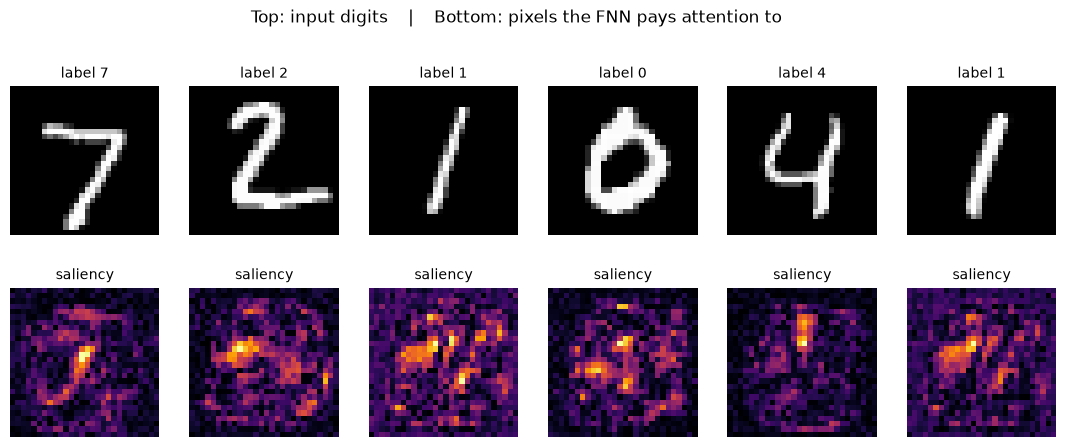

In [9]:
def saliency(model, x):
    # gradient of the predicted-class score with respect to each input pixel
    x = x.to(device).clone().requires_grad_(True)  # ask for gradients on the input itself
    logits = model(x)
    pred = logits.argmax(1)
    score = logits.gather(1, pred.unsqueeze(1)).sum()  # keep only the predicted class's score
    score.backward()
    return x.grad.abs().cpu(), pred.cpu()  # |gradient| = how much each pixel matters


x, y = next(iter(test_loader))
x = x[:6]
sal, pred = saliency(model, x)

fig, axes = plt.subplots(2, 6, figsize=(13.5, 4.8))
for i in range(6):
    axes[0, i].imshow(x[i].squeeze(), cmap="gray")
    axes[1, i].imshow(sal[i].squeeze(), cmap="inferno")  # bright = influential pixel
    axes[1, i].set_title("saliency", fontsize=10)
    for r in (0, 1):
        axes[r, i].axis("off")
fig.suptitle("Top: input digits    |    Bottom: pixels the FNN pays attention to", y=1.02)
plt.show()


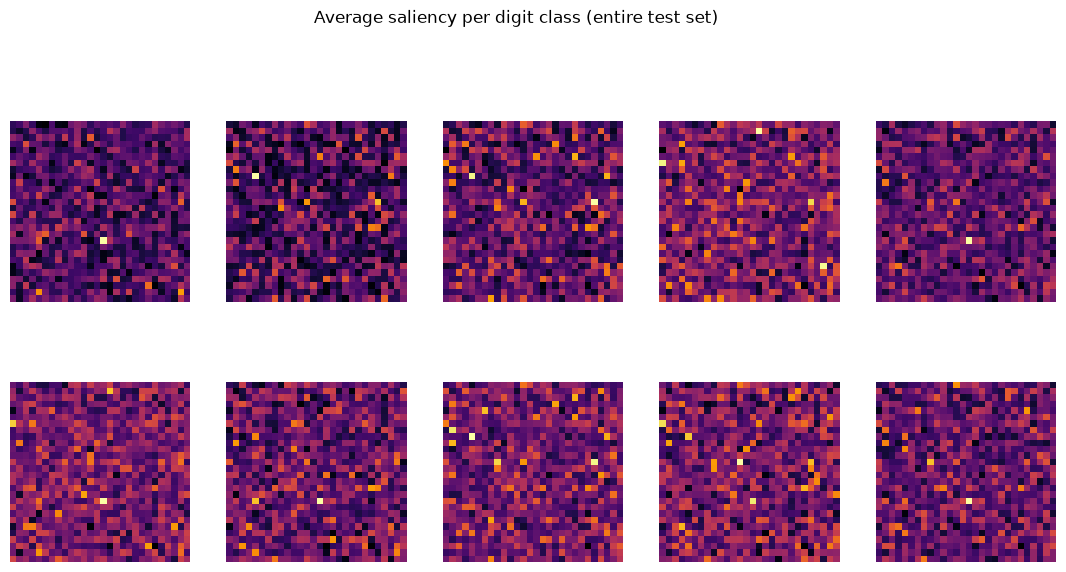

In [16]:
model.eval()
class_sum = torch.zeros(10, 28, 28)   # summed saliency per class
class_count = torch.zeros(10)
for x, y in test_loader:
    x = x.to(device).clone().requires_grad_(True)
    logits = model(x)
    score = logits.gather(1, logits.argmax(1, keepdim=True)).sum()
    score.backward()
    grads = x.grad.abs().mean(1).cpu()          # (B, 28, 28)
    for c in range(10):
        mask = y == c                           # images of class c in this batch
        class_sum[c] += grads[mask].sum(0)
        class_count[c] += mask.sum()

fig, axes = plt.subplots(2, 5, figsize=(13.5, 6.2))
for c in range(10):
    axes.flat[c].imshow(class_sum[c] / class_count[c], cmap="inferno")  # mean saliency per class
    axes.flat[c].axis("off")
fig.suptitle("Average saliency per digit class (entire test set)", y=1.03)
plt.show()


## Scrambled MNIST

Shuffle every pixel to a random spot (same shuffle for every image). If the net were using spatial structure, this should wreck it. So train the *identical* model on scrambled digits:

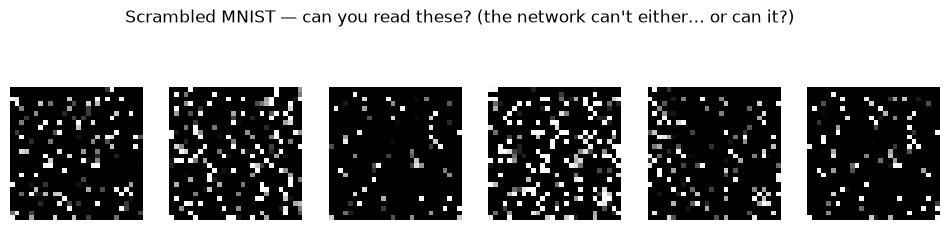

In [ ]:
class ScrambledFNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.fnn = FNN()
        self.register_buffer("perm", torch.randperm(784))  # one fixed pixel shuffle

    def forward(self, x):
        x = x.flatten(1)[:, self.perm].view(-1, 1, 28, 28)  # same shuffle for every image
        return self.fnn(x)


scrambled_model = ScrambledFNN().to(device)

x, _ = next(iter(test_loader))
with torch.no_grad():
    # apply the same scramble by hand, just for display
    scrambled = x.flatten(1)[:, scrambled_model.perm.cpu()].view(-1, 1, 28, 28)
fig, axes = plt.subplots(1, 6, figsize=(12, 2.2))
for ax, img in zip(axes, scrambled[:6]):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.axis("off")
fig.suptitle("Scrambled MNIST — can you read these? (the network can't either… or can it?)", y=1.15)
plt.show()


In [12]:
print("Training the identical architecture on scrambled pixels...\n")
scrambled_history = train(scrambled_model, train_loader, epochs=5)

print()
# scrambled_model scrambles inside forward(), so we feed it clean data
print(f"Clean FNN      on clean      test set: {evaluate(model, test_loader):.2%}")
print(f"Scrambled FNN  on scrambled  test set: {evaluate(scrambled_model, test_loader):.2%}")


Training the identical architecture on scrambled pixels...

epoch 1 | loss 0.2684 | train acc 0.9204 | test acc 0.9567
epoch 2 | loss 0.1004 | train acc 0.9689 | test acc 0.9718
epoch 3 | loss 0.0677 | train acc 0.9787 | test acc 0.9759
epoch 4 | loss 0.0498 | train acc 0.9838 | test acc 0.9795
epoch 5 | loss 0.0382 | train acc 0.9875 | test acc 0.9802

Clean FNN      on clean      test set: 97.92%
Scrambled FNN  on scrambled  test set: 98.02%
